# Algorithmic autonomy, unethical choices, and perceived responsibility

Exploratory secondary analysis of both experiments in Jolly, Dunlop, Parker and Kanse, [Journal of Business Ethics](https://doi.org/10.1007/s10551-025-06034-5). The behavioral analyses estimate effects of assignment to the autonomy-restricting versus autonomy-affording condition, with explicit sensitivity to post-assignment screening. The Study 2 mechanism analyses estimate associations between observed choices and subsequent ratings. The original experiments had their own registrations. This reanalysis is exploratory.

### Run all cells

- **Kaggle:** Import this notebook, select Python and **Accelerator: None**, turn **Internet On** for the dependency installation or OSF download, then choose **Run All**.
- The notebook uses the three original sources listed below and verifies each against its SHA-256. If direct OSF access fails, obtain the author files using the source links and attach them as a Kaggle input where the source terms permit. Keep the original filenames. For an offline Kaggle run, attach all three files and provide the pinned packages in the environment before disabling Internet.
- **Local Jupyter:** Use Python 3.12 or 3.13 and place the three files in `project16_source/` beside the notebook, or set the environment variable `PROJECT16_INPUT_DIR`. Install Jupyter/IPython in the environment first. The setup cell pins the analysis packages and installs missing or mismatched versions by default. Use a fresh kernel.
- The last cell displays a link to **project16_results.zip**. It contains figures as PDF, tables as CSV, and aggregate metadata and checksums. Source data remain outside that ZIP.

In [1]:
# Configure the run before importing analytical packages.
import hashlib
import importlib.metadata
import os
from pathlib import Path
import platform
import subprocess
import sys
import tempfile
import time
import urllib.request
import warnings
import itertools
import json
from urllib.parse import urlsplit, urlunsplit

PINNED = {
    "numpy": "2.3.5",
    "pandas": "2.2.3",
    "scipy": "1.17.0",
    "matplotlib": "3.10.8",
    "statsmodels": "0.14.6",
    "pyreadstat": "1.3.2",
    "patsy": "1.0.3",
    "narwhals": "2.29.0",
}
INSTALL_PINNED_PACKAGES = True
ALLOW_OSF_DOWNLOADS = True
SEED = 16026
BOOTSTRAPS = 2000

def installed_version(package):
    try:
        return importlib.metadata.version(package)
    except importlib.metadata.PackageNotFoundError:
        return None

mismatched = [f"{package}=={version}" for package, version in PINNED.items()
              if installed_version(package) != version]
if mismatched:
    loaded = [requirement.split("==")[0] for requirement in mismatched
              if requirement.split("==")[0] in sys.modules]
    if not INSTALL_PINNED_PACKAGES:
        raise RuntimeError("Preinstall the pinned packages: " + ", ".join(mismatched))
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *mismatched])
    if loaded:
        raise RuntimeError("Packages changed after import. Restart the kernel and choose Run All.")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
from scipy.stats import norm
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.miscmodels.ordinal_model import OrderedModel
from statsmodels.stats.multitest import multipletests
import pyreadstat
from IPython.display import display, Markdown, FileLink

BASE = Path("/kaggle/working") if Path("/kaggle/working").is_dir() else Path.cwd()
DATA = BASE / "project16_source"
DATA.mkdir(exist_ok=True)
OUT = Path(tempfile.mkdtemp(prefix="project16_run_", dir=BASE))
INPUT_ROOTS = [DATA, BASE / "data" / "raw", BASE, Path("/kaggle/input")]
if os.environ.get("PROJECT16_INPUT_DIR"):
    INPUT_ROOTS.insert(0, Path(os.environ["PROJECT16_INPUT_DIR"]).expanduser())
versions = {"python": platform.python_version(),
            **{package: installed_version(package) for package in PINNED}}
print(versions)
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False,
                     "pdf.fonttype": 42})
artifacts = []

def report_artifact(frame_or_figure, name, caption, kind, extension):
    if any(artifact["id"] == name for artifact in artifacts):
        raise ValueError(f"Duplicate artifact: {name}")
    path = OUT / f"{name}.{extension}"
    if kind == "table":
        frame_or_figure.to_csv(path, index=False)
    else:
        frame_or_figure.savefig(path, bbox_inches="tight")
    display(Markdown(f"**{name}** — {caption}"))
    display(frame_or_figure)
    artifacts.append({"id": name, "kind": kind, "caption": caption, "file": path.name})

def table(frame, name, caption):
    report_artifact(frame.reset_index(drop=True), name, caption, "table", "csv")

def figure(fig, name, caption):
    if not getattr(fig, "_manual_layout", False):
        fig.tight_layout()
    report_artifact(fig, name, caption, "figure", "pdf")
    plt.close(fig)

def forest(df, labels, xlabel, name, caption):
    fig, ax = plt.subplots(figsize=(8, max(3, len(df) * .32 + 1)))
    y = np.arange(len(df))
    ax.hlines(y, df["low"], df["high"], color="#245b78", linewidth=1.3)
    ax.plot(df["estimate"], y, "o", color="#245b78")
    ax.axvline(0, color="gray", lw=1)
    ax.set_yticks(y, labels)
    ax.invert_yaxis()
    ax.set_xlabel(xlabel)
    figure(fig, name, caption)

def approx_derivative(fun, params):
    params = np.asarray(params, dtype=float)
    gradient = []
    for index, value in enumerate(params):
        step = 1e-5 * max(1, abs(value))
        plus, minus = params.copy(), params.copy()
        plus[index] += step
        minus[index] -= step
        gradient.append((fun(plus) - fun(minus)) / (2 * step))
    return np.asarray(gradient).T

{'python': '3.13.18', 'numpy': '2.3.5', 'pandas': '2.2.3', 'scipy': '1.17.0', 'matplotlib': '3.10.8', 'statsmodels': '0.14.6', 'pyreadstat': '1.3.2', 'patsy': '1.0.3', 'narwhals': '2.29.0'}


## Obtain the original study inputs

- [Experiment 1 for OSF.sav](https://osf.io/download/8rzjb/?view_only=4f847ddbc31d490b90917809c4e07c38)
- [Experiment 2 for OSF.sav](https://osf.io/download/60f133a8f1369300b1795897/?view_only=4f847ddbc31d490b90917809c4e07c38)
- [Exp2Data.csv](https://osf.io/download/60f13dbe0316ba00c63ce24a/?view_only=4f847ddbc31d490b90917809c4e07c38)

The submitted teaching repository already contains `Exp2Data.csv` under `data/raw/`. Consult the [original OSF project](https://osf.io/phg82/?view_only=4f847ddbc31d490b90917809c4e07c38) for access and reuse terms. The final results bundle contains the input hashes and a provenance record.

In [2]:
SOURCES = [{'name': 'Experiment 2 for OSF.sav', 'path': '/Data files/Main Studies/Experiment 2 for OSF.sav', 'url': 'https://osf.io/download/60f133a8f1369300b1795897/?view_only=4f847ddbc31d490b90917809c4e07c38', 'sha256': '40e6e9c611dbf1e60b654cdd79378b7fb059bca3938a229c0d62143bd84cbdb0'}, {'name': 'Exp2Data.csv', 'path': '/Data files/Main Studies/Hypothesis tests/Experiment 2/Exp2Data.csv', 'url': 'https://osf.io/download/60f13dbe0316ba00c63ce24a/?view_only=4f847ddbc31d490b90917809c4e07c38', 'sha256': '0c4adf6a554c47e64aab468e3ac65eb822cdc30c52b48cf920df3637faa80c4b'}, {'name': 'Experiment 1 for OSF.sav', 'path': '/Data files/Main Studies/Experiment 1 for OSF.sav', 'url': 'https://osf.io/download/8rzjb/?view_only=4f847ddbc31d490b90917809c4e07c38', 'sha256': 'f60ec0f8e4d151bebe0e7f17218d734865abdf7377f1ed452d55c26647e5c4c6'}]

def checksum(path):
    return hashlib.sha256(path.read_bytes()).hexdigest()

def get_verified_source(record):
    name, expected = record["name"], record["sha256"]
    candidates = [root / name for root in INPUT_ROOTS]
    kaggle_input = Path("/kaggle/input")
    if kaggle_input.is_dir():
        candidates.extend(sorted(kaggle_input.rglob(name)))
    for candidate in dict.fromkeys(candidates):
        if candidate.is_file():
            if checksum(candidate) == expected:
                return candidate, "local or attached"
            print(f"{name}: skipped a local copy with a different checksum.")

    detail = "automatic downloads disabled"
    if ALLOW_OSF_DOWNLOADS:
        for attempt in range(2):
            print(f"{name}: OSF download attempt {attempt + 1}/2.", flush=True)
            try:
                request = urllib.request.Request(record["url"], headers={
                    "User-Agent": "Project16-Reproducibility/2.0",
                })
                with urllib.request.urlopen(request, timeout=25) as response:
                    content = response.read()
                if hashlib.sha256(content).hexdigest() != expected:
                    detail = "downloaded response failed the source checksum"
                else:
                    destination = DATA / name
                    with tempfile.NamedTemporaryFile(dir=DATA, delete=False) as staging:
                        staging.write(content)
                        staged_path = Path(staging.name)
                    staged_path.replace(destination)
                    return destination, "OSF download"
            except OSError as error:
                detail = type(error).__name__
            if attempt == 0:
                time.sleep(2)
    raise RuntimeError(f"{name}: {detail}. Obtain the exact original file using the links above, "
                       "attach it to Kaggle or place it in project16_source/, and rerun.")

source_files, provenance = {}, []
for record in SOURCES:
    path, mode = get_verified_source(record)
    source_files[record["name"]] = path
    url = urlsplit(record["url"])
    provenance.append({"file": record["name"], "sha256": record["sha256"],
                       "source": urlunsplit(url._replace(query="")), "input_mode": mode})
    print(f"{record['name']}: verified ({mode}).")

raw, meta = {}, {}
for study in (1, 2):
    raw[study], meta[study] = pyreadstat.read_sav(source_files[f"Experiment {study} for OSF.sav"])
if [len(raw[study]) for study in (1, 2)] != [276, 256]:
    raise ValueError("Author releases should contain 276 and 256 retained participants.")
(OUT / "source_provenance.json").write_text(json.dumps(provenance, indent=2))
(OUT / "variable_labels.json").write_text(json.dumps({
    str(study): dict(zip(meta[study].column_names, meta[study].column_labels, strict=True))
    for study in (1, 2)
}, indent=2))

Experiment 2 for OSF.sav: verified (local or attached).
Exp2Data.csv: verified (local or attached).
Experiment 1 for OSF.sav: verified (local or attached).


17109

## Validate assignment, outcomes, and responsibility measures

In [3]:
# Validate coding and construct measures
# Method M2 | All RQs
items=['BookingFee','CheckOut','Points','WrongRoom']; studies={}; audit=[]
hh=['PHfair1_R','PHfair6','PHfair8_R','PHgree2','PHgree7_R','PHmode6_R','PHmode8_R','PHsinc4','PHsinc5_R','PHsinc6']
for s,d in raw.items():
    z=pd.DataFrame(index=d.index);z['id']=[f'S{s}_{i}' for i in d.index];z['study']=s
    labels=meta[s].variable_value_labels['Condition']
    low=[v for v,label in labels.items() if 'low' in label.lower()]
    assert len(low)==1
    assert d.Condition.notna().all() and set(d.Condition) == set(labels), 'Unexpected assignment codes'
    z['T']=(d.Condition==low[0]).astype(int) # 1 restricted, 0 affording
    z['A']=1-z['T']
    for item in items:
        c='Dilemma_'+item
        # Study 2 option codes differ from the stale SPSS text for Points/WrongRoom.
        value_labels=meta[s].variable_value_labels[c]
        top_codes=[v for v,label in value_labels.items() if 'top' in label.lower()]
        assert len(top_codes)==1, 'Ambiguous Top Reply code'
        unethical=top_codes[0]
        z[item]=d[c].map({unethical:1,3-unethical:0})
        assert np.allclose(z[item],d[c+'_recode'],equal_nan=True), c
    z['Y']=z[items].sum(axis=1,min_count=4);z['rate']=z.Y/4
    assert np.allclose(z.Y,d.UnethicalCount,equal_nan=True)
    z['HH']=d[hh].mean(axis=1);assert np.allclose(z.HH,d.HonestyHumility,equal_nan=True)
    if s==1:
        for t in [1,2]:z[f'self{t}']=d[[f'T{t}Responsibility{i}' for i in range(1,5)]].mean(axis=1)
    else:
        for t in [1,2]:
            for actor,col in [('designer','Designer'),('algorithm','Algorithm'),('manager','Execs'),('self','Themselves')]:z[f'{actor}{t}']=d[f'T{t}NC{col}']
            cs=[f'{a}{t}' for a in ['designer','algorithm','manager']]
            # Strict complete cases prevent changing the number of candidates in the maximum.
            z[f'max{t}']=z[cs].max(axis=1,skipna=False);z[f'mean{t}']=z[cs].mean(axis=1,skipna=False)
            z[f'gap{t}']=z[f'max{t}']-z[f'self{t}']
    z['hex_pass']=d.HEXACOAttention1.eq(2)&d.HEXACOAttention2.eq(5)
    role=d.HACheck1.where(z['T'].eq(0),d.LACheck1)
    instruct=d.HACheck2.where(z['T'].eq(0),d.LACheck2)
    z['first_pass']=z.hex_pass & role.eq(4) & instruct.eq(np.where(z['T'].eq(1),3,2))
    studies[s]=z
    audit.append({'study':s,'n':len(z),'incomplete_choices':int(z.Y.isna().sum()),'restricted':int(z['T'].sum()),'affording':int(z['T'].eq(0).sum()),'count_mean':z.Y.mean(),'count_variance':z.Y.var()})
expected_arms = {1: (136, 140), 2: (132, 124)}
for row in audit:
    assert (row['restricted'], row['affording']) == expected_arms[row['study']]
table(pd.DataFrame(audit),'AUDIT','Coding and sample checks; all binary recodes agree with author variables')

**AUDIT** — Coding and sample checks; all binary recodes agree with author variables

,study,n,incomplete_choices,restricted,affording,count_mean,count_variance
0,1,276,0,136,140,1.539855,2.234769
1,2,256,0,132,124,1.210938,2.120037


## Benchmark the published H1 and H2 component estimates

Negative-binomial outcome regressions and linear first-stage regressions provide a component-level benchmark for the published path estimates. The analysis records convergence, differences from the printed values, and benchmark status. The original joint Mplus fit and its bias-corrected inference require the original Mplus models.

In [4]:
# Reproduce anchor benchmarks
# Method M3 | All RQs
repro=[]
for s,z in studies.items():
    # Original autonomy direction, A=1 affording. Joint Mplus ML is approximated by component regressions.
    formula='Y ~ A + self1'+(' + HH' if s==1 else '')
    fit=smf.negativebinomial(formula,z).fit(disp=False, maxiter=300)
    if not fit.mle_retvals['converged']:
        raise RuntimeError(f'Study {s}: anchor negative-binomial benchmark did not converge.')
    for term,target in [('A',-.78 if s==1 else -1.10)]:
        value=float(fit.params[term]);repro.append({'study':s,'benchmark':'NB autonomy coefficient','published':target,'recomputed':value,'difference':value-target,'within_0.03':abs(value-target)<.03})
    a=smf.ols('self1 ~ A',z).fit().params['A']; ab=a*fit.params['self1']
    target=-.044 if s==1 else -.083
    repro.append({'study':s,'benchmark':'NB path a times b','published':target,'recomputed':ab,'difference':ab-target,'within_0.03':abs(ab-target)<.03})
table(pd.DataFrame(repro),'REPRODUCTION','Component-regression approximation; discrepancies must be reviewed before publication')
print('Coding caveat: Study 2 Points/WrongRoom use raw code 1 for Top Reply; its SPSS text says code 2. Value labels and stored recodes agree, so these take precedence.')
print('Source caveat: Exp1Data.csv has six columns; its .inp lists five names. The SAV labels and SPSS recodes are used rather than silently assigning an incorrect CSV schema.')

**REPRODUCTION** — Component-regression approximation; discrepancies must be reviewed before publication

,study,benchmark,published,recomputed,difference,within_0.03
0,1,NB autonomy coefficient,-0.780,-0.778612,0.001388,True
1,1,NB path a times b,-0.044,-0.043748,0.000252,True
2,2,NB autonomy coefficient,-1.100,-1.103535,-0.003535,True
3,2,NB path a times b,-0.083,-0.083155,-0.000155,True


Coding caveat: Study 2 Points/WrongRoom use raw code 1 for Top Reply; its SPSS text says code 2. Value labels and stored recodes agree, so these take precedence.
Source caveat: Exp1Data.csv has six columns; its .inp lists five names. The SAV labels and SPSS recodes are used rather than silently assigning an incorrect CSV schema.


## Behavioral multiverse

Estimate the restricted-minus-affording difference in mean unethical-choice probability with outcome models for bounded counts, an ordinal model, and repeated-item GEE with participant clustering and fixed dilemma effects. OLS is the transparent released-sample reference. Negative binomial and Poisson fits are sensitivity models. Report the complete specification ledger and pointwise uncertainty. Model fits sharing data and estimating similar contrasts provide dependent evidence.

In [5]:
# Define screening and estimation functions
# Method M4–M6 | RQ1 and RQ5
rules={'released':lambda z:np.ones(len(z),dtype=bool),'hex_perfect':lambda z:z.hex_pass,'first_pass_perfect':lambda z:z.first_pass}
def contrast(z,outcome,extra=''):
    f=smf.ols(f'{outcome} ~ T'+extra,z).fit(cov_type='HC3');ci=f.conf_int().loc['T']
    return {'estimate':f.params['T'],'low':ci.iloc[0],'high':ci.iloc[1],'p':f.pvalues['T'],'n':int(f.nobs)}
def model_effect(z,kind,adjust):
    cols=['Y','T']+items+(['HH'] if adjust else [])
    z=z.dropna(subset=cols).copy()
    if z['T'].nunique() != 2:
        raise ValueError('Specification requires observations in both arms.')
    rhs='T'+(' + HH' if adjust else '')
    if kind=='GEE':
        q=z.melt(id_vars=['id','T','HH'],value_vars=items,var_name='dilemma',value_name='choice')
        fit=smf.gee('choice ~ '+rhs+' + C(dilemma)',groups='id',data=q,family=sm.families.Binomial(),cov_struct=sm.cov_struct.Exchangeable()).fit()
        X0=np.array(fit.model.exog,copy=True);X1=X0.copy();ti=fit.model.exog_names.index('T');X0[:,ti]=0;X1[:,ti]=1
    elif kind=='Ordinal':
        names=['T']+(['HH'] if adjust else [])
        fit=OrderedModel(z.Y.astype(int),z[names],distr='logit').fit(method='bfgs',disp=False,maxiter=500)
        X0=z[names].assign(T=0);X1=z[names].assign(T=1)
    else:
        if kind=='OLS':fit=smf.ols('rate ~ '+rhs,z.assign(rate=z.Y/4)).fit(cov_type='HC3')
        elif kind=='NB':fit=smf.negativebinomial('Y ~ '+rhs,z).fit(disp=False,maxiter=500,cov_type='HC0')
        elif kind=='Poisson':fit=smf.glm('Y ~ '+rhs,z,family=sm.families.Poisson()).fit(cov_type='HC0')
        else:fit=smf.glm('rate ~ '+rhs,z.assign(rate=z.Y/4),family=sm.families.Binomial(),var_weights=np.repeat(4,len(z))).fit(cov_type='HC0')
        X0=np.array(fit.model.exog,copy=True);X1=X0.copy();ti=fit.model.exog_names.index('T');X0[:,ti]=0;X1[:,ti]=1
    par=np.asarray(fit.params)
    def effect(p):
        if kind=='Ordinal':
            v=np.sort(z.Y.unique())/4
            return float(np.mean(fit.model.predict(p,exog=X1)@v-fit.model.predict(p,exog=X0)@v))
        k=X0.shape[1];b=p[:k]
        if kind=='OLS':g=lambda x:x
        elif kind in ['GEE','Binomial']:g=lambda x:scipy.special.expit(x)
        else:g=lambda x:np.exp(x)/4
        return float(np.mean(g(X1@b)-g(X0@b)))
    est=effect(par);grad=approx_derivative(lambda p:np.array([effect(p)]),par).ravel()
    variance=float(grad@np.asarray(fit.cov_params())@grad)
    if not np.isfinite(est) or not np.isfinite(variance) or variance <= 0:
        raise ValueError('Invalid marginal effect or variance.')
    se=np.sqrt(variance)
    converged=bool(getattr(fit,'converged',getattr(fit,'mle_retvals',{}).get('converged',True)))
    return {'estimate':est,'low':est-1.96*se,'high':est+1.96*se,'native_T':float(fit.params['T']),
      'p':2*norm.sf(abs(est/se)) if se>0 else np.nan,'n':len(z),'converged':converged}

**RQ1_T1** — Full planned ledger; effects are changes in average choice probability, restricted minus affording

,study,screen,HH_adjusted,model,estimate,low,high,native_T,p,n,converged,warnings,status,curve_rank
0,1,released,False,OLS,0.306513,0.225236,0.387789,0.306513,1.450379e-13,276,True,,ok,31.0
1,1,released,False,Binomial,0.306513,0.225829,0.387197,1.348378,9.629223e-14,276,True,,ok,29.0
2,1,released,False,Poisson,0.306513,0.225829,0.387197,0.837370,9.629223e-14,276,True,,ok,32.0
3,1,released,False,NB,0.306513,0.225829,0.387197,0.837370,9.629223e-14,276,True,,ok,30.0
4,1,released,False,Ordinal,0.285776,0.203886,0.367666,1.474895,7.924271e-12,276,True,,ok,5.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
67,2,first_pass_perfect,True,Binomial,0.319928,0.234797,0.405058,1.651378,1.760137e-13,227,True,,ok,31.0
68,2,first_pass_perfect,True,Poisson,0.319895,0.234790,0.405000,1.184470,1.740985e-13,227,True,,ok,30.0
69,2,first_pass_perfect,True,NB,0.320498,0.235317,0.405679,1.186449,1.648217e-13,227,True,,ok,36.0
70,2,first_pass_perfect,True,Ordinal,0.280829,0.193281,0.368376,1.577326,3.233421e-10,227,True,,ok,6.0


**RQ1_F1** — Marginal effects; pointwise 95% delta intervals; colors identify outcome models, ranks identify specifications

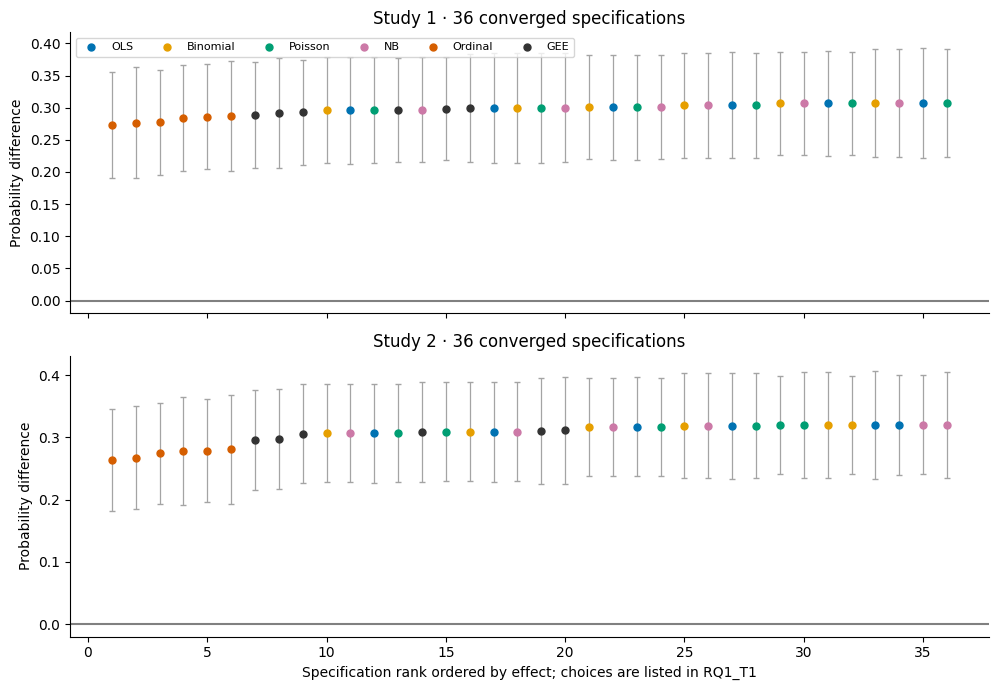

**RQ1_T2** — Descriptive proportions among converged specifications; correlated fits are not independent evidence

,study,planned,converged,failed_or_nonconverged,positive_share,positive_CI_excludes_zero_share,median_effect,min_effect,max_effect
0,1,36,36,0,1.0,1.0,0.299469,0.273085,0.307227
1,2,36,36,0,1.0,1.0,0.309713,0.263477,0.320498


**RQ1_F2** — Released-sample count distributions; bars show observed proportions

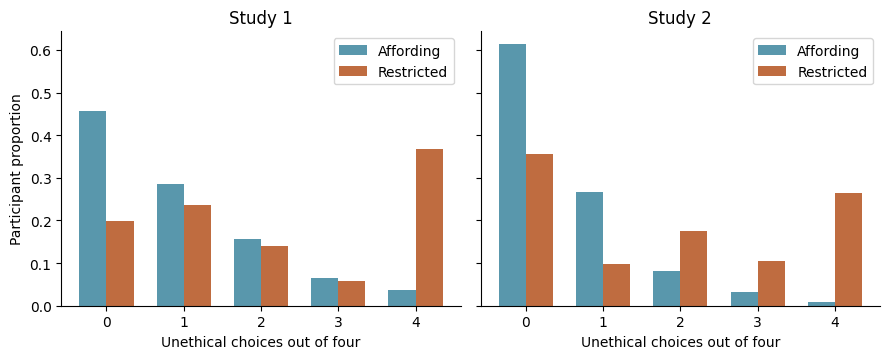

In [6]:
# Run complete model multiverse
# Method M5–M6 | RQ1
rows=[]
for s,z in studies.items():
 for rule,mask in rules.items():
  for adj,kind in itertools.product([False,True],['OLS','Binomial','Poisson','NB','Ordinal','GEE']):
   rec={'study':s,'screen':rule,'HH_adjusted':adj,'model':kind}
   try:
    with warnings.catch_warnings(record=True) as ws:
     warnings.simplefilter('always'); rec.update(model_effect(z.loc[mask(z)],kind,adj))
     rec['warnings']='; '.join(sorted(set(str(w.message) for w in ws)))
    rec['status']='ok' if rec['converged'] else 'not_converged'
   except Exception as exc:rec.update(status='failed',warnings=str(exc))
   rows.append(rec)
spec=pd.DataFrame(rows)
spec['curve_rank'] = np.nan
# Treat effects that agree to eight decimals as tied and order them by their model and screen labels.
valid = spec.loc[spec.status.eq('ok')].assign(rounded_effect=lambda rows: rows.estimate.round(8))
order = valid.sort_values(['study', 'rounded_effect', 'screen', 'HH_adjusted', 'model'])
spec.loc[order.index, 'curve_rank'] = order.groupby('study').cumcount() + 1
table(spec,'RQ1_T1','Full planned ledger; effects are changes in average choice probability, restricted minus affording')
ok=spec.loc[spec.status.eq('ok')].copy()
fig,axes=plt.subplots(2,1,figsize=(10,7),sharex=True)
colors=dict(zip(['OLS','Binomial','Poisson','NB','Ordinal','GEE'],['#0072B2','#E69F00','#009E73','#CC79A7','#D55E00','#333333']))
for ax,(s,g) in zip(axes,ok.groupby('study')):
 g=g.sort_values('curve_rank');x=g.curve_rank.to_numpy()
 ax.errorbar(x,g.estimate,yerr=[g.estimate-g.low,g.high-g.estimate],fmt='none',capsize=2,color='#a4a4a4',lw=.9,zorder=1)
 for model,col in colors.items():
  v=g[g.model.eq(model)];ax.scatter(v.curve_rank,v.estimate,color=col,s=25,label=model,zorder=2)
 ax.axhline(0,color='gray');ax.set_title(f'Study {s} · {len(g)} converged specifications');ax.set_ylabel('Probability difference')
 ax.set_ylim(min(-.02,g.low.min()-.02),g.high.max()+.025)
axes[0].legend(ncol=6,fontsize=8,loc='upper left')
axes[1].set_xlabel('Specification rank ordered by effect; choices are listed in RQ1_T1')
figure(fig,'RQ1_F1','Marginal effects; pointwise 95% delta intervals; colors identify outcome models, ranks identify specifications')
if ok['study'].nunique() != len(studies):
    raise RuntimeError('No valid behavioral specifications for at least one study.')
summary=[]
for s,g in spec.groupby('study'):
 v=g[g.status.eq('ok')];summary.append({'study':s,'planned':len(g),'converged':len(v),'failed_or_nonconverged':len(g)-len(v),'positive_share':(v.estimate>0).mean(),'positive_CI_excludes_zero_share':(v.low>0).mean(),'median_effect':v.estimate.median(),'min_effect':v.estimate.min(),'max_effect':v.estimate.max()})
table(pd.DataFrame(summary),'RQ1_T2','Descriptive proportions among converged specifications; correlated fits are not independent evidence')
fig,axes=plt.subplots(1,2,figsize=(9,3.7),sharey=True)
for ax,(s,z) in zip(axes,studies.items()):
 for t,col in [(0,'#5997ac'),(1,'#bf6c40')]:
  freq=z.loc[z['T'].eq(t),'Y'].value_counts(normalize=True).reindex(range(5),fill_value=0)
  ax.bar(np.arange(5)+(t-.5)*.35,freq,width=.35,label=['Affording','Restricted'][t],color=col)
 ax.set_title(f'Study {s}');ax.set_xlabel('Unethical choices out of four');ax.set_xticks(range(5));ax.legend()
axes[0].set_ylabel('Participant proportion')
figure(fig,'RQ1_F2','Released-sample count distributions; bars show observed proportions')

## Responsibility by actor and rating definition

Study 2 ratings are independent responses on a five-point scale. Average and maximum external ratings summarize different aspects of attribution. The external-minus-self gap is a descriptive contrast. It can change without a fixed amount of responsibility moving from one actor to another.

**RQ2_T1** — Study 2 shared complete cases; HC3 95% intervals in rating units; Holm across 14 contrasts

,time,measure,estimate,low,high,p,n,p_holm
0,1,self,-0.575024,-0.844561,-0.305488,2.897718e-05,256,5.795436e-05
1,1,designer,0.637341,0.370534,0.904148,2.842192e-06,256,1.421096e-05
2,1,algorithm,0.646628,0.373441,0.919814,3.497570e-06,256,1.421096e-05
3,1,manager,0.490469,0.221829,0.759109,3.457036e-04,256,3.457036e-04
4,1,mean,0.591479,0.378832,0.804126,4.990341e-08,256,4.990341e-07
5,1,max,0.605327,0.363801,0.846854,9.006900e-07,256,7.205520e-06
6,1,gap,1.180352,0.797877,1.562826,1.460826e-09,256,1.899074e-08
7,2,self,-0.653715,-0.922749,-0.384680,1.912785e-06,256,1.147671e-05
8,2,designer,0.692815,0.429291,0.956340,2.566015e-07,256,2.309413e-06
9,2,algorithm,0.637341,0.358400,0.916282,7.525865e-06,256,2.257759e-05


**RQ2_F1** — Study 2 T2 actor and aggregation contrasts; same participants for every row

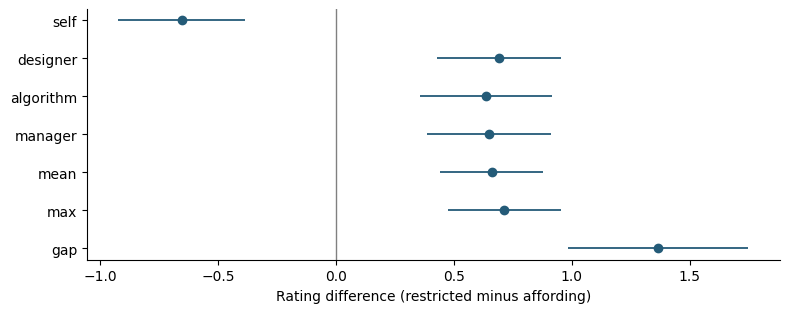

**RQ2_F2** — Mechanical maximum inflation; high values indicate concentration of blame on selected actors

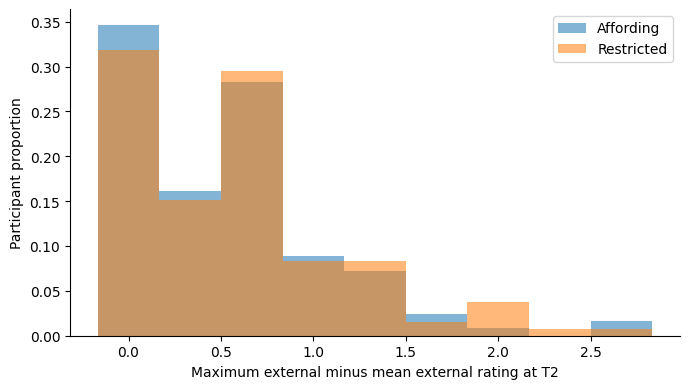

**RQ2_T2** — Study 2 T2 Spearman correlations on identical complete cases; independent ratings need not sum to a constant

,actor,self2,designer2,algorithm2,manager2
0,self2,1.000000,-0.230177,-0.126293,-0.162622
1,designer2,-0.230177,1.000000,0.688289,0.529116
2,algorithm2,-0.126293,0.688289,1.000000,0.335549
3,manager2,-0.162622,0.529116,0.335549,1.000000


In [7]:
# Compare responsibility operationalizations
# Method M7 | RQ2
z=studies[2];actor_names=['self','designer','algorithm','manager','mean','max','gap']
common=z.dropna(subset=[f'{a}{t}' for a in actor_names for t in [1,2]])
rr=[]
for t,a in itertools.product([1,2],actor_names):rr.append({'time':t,'measure':a,**contrast(common,f'{a}{t}')})
resp=pd.DataFrame(rr);resp['p_holm']=multipletests(resp.p,method='holm')[1]
table(resp,'RQ2_T1','Study 2 shared complete cases; HC3 95% intervals in rating units; Holm across 14 contrasts')
g=resp[resp.time.eq(2)]
forest(g,g.measure,'Rating difference (restricted minus affording)','RQ2_F1','Study 2 T2 actor and aggregation contrasts; same participants for every row')
fig,ax=plt.subplots(figsize=(7,4))
for t in [0,1]:
 vals=common.loc[common['T'].eq(t),'max2']-common.loc[common['T'].eq(t),'mean2']
 ax.hist(vals,bins=np.arange(-1/6,3.01,1/3),weights=np.ones(len(vals))/len(vals),alpha=.55,label=['Affording','Restricted'][t])
ax.set_xlabel('Maximum external minus mean external rating at T2');ax.set_ylabel('Participant proportion');ax.legend()
figure(fig,'RQ2_F2','Mechanical maximum inflation; high values indicate concentration of blame on selected actors')
corr=common[[a+'2' for a in actor_names[:4]]].corr(method='spearman').rename_axis('actor').reset_index()
table(corr,'RQ2_T2','Study 2 T2 Spearman correlations on identical complete cases; independent ratings need not sum to a constant')

## Dilemma and study heterogeneity

Treat the four dilemmas and two studies as fixed. The pooled interaction model uses clustered standard errors and Holm adjustment for the two joint tests. Leave-one-dilemma-out estimates assess dependence on individual dilemmas. For the interaction tests, wide intervals and limited sample size constrain conclusions about similarity.

**RQ3_F1** — Eight item-specific HC3 pointwise 95% intervals; participants recur across items

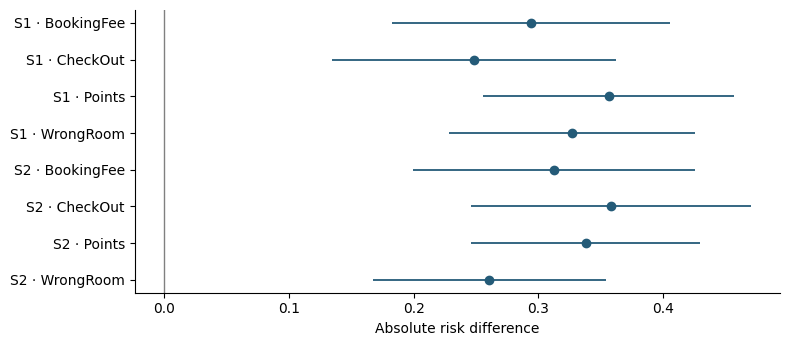

**RQ3_T1** — Joint tests in saturated linear probability model; participant-cluster covariance, Holm over two tests

,test,chi2,df,p,participants,p_holm
0,Any treatment by dilemma heterogeneity,7.099901,6,0.311707,532,0.623414
1,Any treatment by study heterogeneity,4.301898,4,0.366688,532,0.623414


**RQ3_F2** — Observed choice rates and nonmissing denominators by study and dilemma

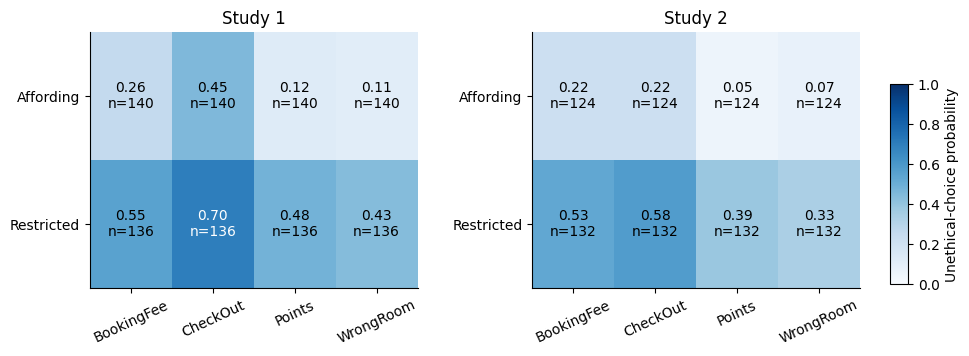

**RQ3_T2** — Leave-one-dilemma-out mean-choice effects, HC3 intervals; all rows remain correlated

,study,omitted,estimate,low,high,p,n
0,1,None,0.306513,0.225238,0.387787,1.450379e-13,276
1,1,BookingFee,0.310574,0.226279,0.394870,5.153374e-13,276
2,1,CheckOut,0.325840,0.240137,0.411544,9.217308e-14,276
3,1,Points,0.289846,0.205248,0.374444,1.879171e-11,276
4,1,WrongRoom,0.299790,0.216745,0.382835,1.490444e-12,276
5,2,None,0.317326,0.238049,0.396604,4.322913e-15,256
6,2,BookingFee,0.318915,0.239214,0.398616,4.414787e-15,256
7,2,CheckOut,0.303763,0.223470,0.384057,1.217582e-13,256
8,2,Points,0.310443,0.227554,0.393332,2.125654e-13,256
9,2,WrongRoom,0.336184,0.250205,0.422164,1.808953e-14,256


In [8]:
# Assess dilemma and study heterogeneity
# Method M8 | RQ3
itemrows=[]
for s,z in studies.items():
 for item in items:itemrows.append({'study':s,'dilemma':item,**contrast(z,item)})
it=pd.DataFrame(itemrows)
forest(it,[f'S{x.study} · {x.dilemma}' for x in it.itertuples()],'Absolute risk difference','RQ3_F1','Eight item-specific HC3 pointwise 95% intervals; participants recur across items')
it.to_csv(OUT/'RQ3_item_effects_source.csv',index=False)
long=pd.concat([z.melt(id_vars=['id','study','T'],value_vars=items,var_name='dilemma',value_name='choice') for z in studies.values()],ignore_index=True).dropna()
fit=smf.ols('choice ~ T*C(study)*C(dilemma)',long).fit(cov_type='cluster',cov_kwds={'groups':long.id})
terms=list(fit.params.index);tests=[]
for label,selector in [('Any treatment by dilemma heterogeneity',lambda x:'T:' in x and 'C(dilemma)' in x),('Any treatment by study heterogeneity',lambda x:'T:' in x and 'C(study)' in x)]:
 indices=[i for i,t in enumerate(terms) if selector(t)]
 R=np.eye(len(terms))[indices];w=fit.wald_test(R,scalar=True)
 tests.append({'test':label,'chi2':float(w.statistic),'df':len(indices),'p':float(w.pvalue),'participants':long.id.nunique()})
tests=pd.DataFrame(tests);tests['p_holm']=multipletests(tests.p,method='holm')[1]
table(tests,'RQ3_T1','Joint tests in saturated linear probability model; participant-cluster covariance, Holm over two tests')
fig,axes=plt.subplots(1,2,figsize=(10,4))
for ax,(s,z) in zip(axes,studies.items()):
 mat=np.array([[z.loc[z['T'].eq(t),i].mean() for i in items] for t in [0,1]])
 image=ax.imshow(mat,vmin=0,vmax=1,cmap='Blues',aspect='auto')
 for t,i in itertools.product(range(2),range(4)):
  nn=z.loc[z['T'].eq(t),items[i]].notna().sum();ax.text(i,t,f'{mat[t,i]:.2f}\nn={nn}',ha='center',va='center',color='white' if mat[t,i]>.6 else 'black')
 ax.set_xticks(range(4),items,rotation=25);ax.set_yticks([0,1],['Affording','Restricted']);ax.set_title(f'Study {s}')
fig.subplots_adjust(left=.10,right=.87,bottom=.24,wspace=.35)
cax=fig.add_axes([.90,.25,.018,.5]);fig.colorbar(image,cax=cax,label='Unethical-choice probability')
fig._manual_layout=True
figure(fig,'RQ3_F2','Observed choice rates and nonmissing denominators by study and dilemma')
loo=[]
for s,z in studies.items():
 for omitted in ['None']+items:
  keep=[i for i in items if i!=omitted];q=z.copy();q['loo']=q[keep].mean(axis=1,skipna=False)
  loo.append({'study':s,'omitted':omitted,**contrast(q,'loo')})
table(pd.DataFrame(loo),'RQ3_T2','Leave-one-dilemma-out mean-choice effects, HC3 intervals; all rows remain correlated')

## Exploratory mediation and measurement diagnostics

Study 1 examines general self-responsibility. Study 2 measures attribution for adverse customer outcomes. Report estimates within each study and retain the residual-correlation sensitivity analysis for the linear decompositions. The mediator is post-assignment. Later attribution models conditioned on earlier post-assignment ratings describe conditional associations.

**RQ4_T1** — Linear exploratory a×b on mean-choice scale; 2000 participant bootstraps, percentile 95% intervals

,study,mediator_T1,a,b,estimate,low,high,n,bootstrap_n
0,1,self1,-0.476418,-0.049872,0.023760,-0.008326,0.057498,276,2000
1,2,self1,-0.575024,-0.044762,0.025739,0.003622,0.055288,256,2000
2,2,designer1,0.637341,0.027692,0.017649,-0.004954,0.043359,256,2000
3,2,algorithm1,0.646628,0.014398,0.009310,-0.014610,0.035989,256,2000
4,2,manager1,0.490469,0.006437,0.003157,-0.014805,0.022447,256,2000
5,2,mean1,0.591479,0.025905,0.015322,-0.011610,0.043609,256,2000
6,2,max1,0.605327,0.013527,0.008188,-0.014377,0.031781,256,2000
7,2,gap1,1.180352,0.027865,0.032890,0.003616,0.065838,256,2000


**RQ4_F1** — Linear structural sensitivity at fixed ρ; curves are not causal effects or confidence bands

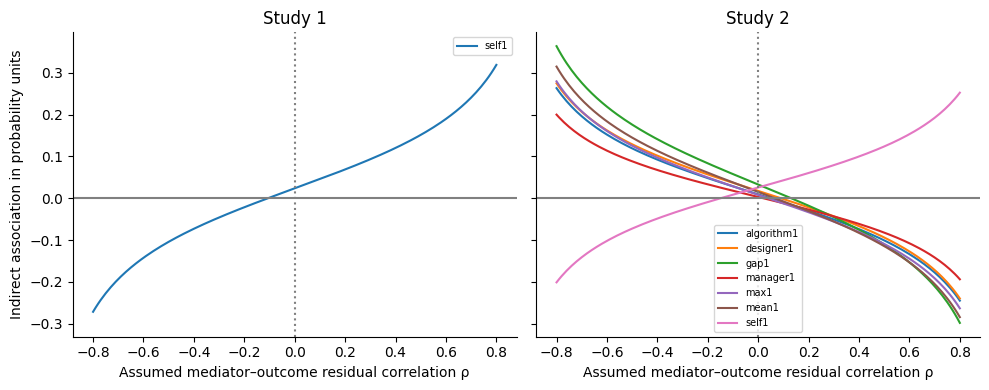

In [9]:
# Estimate exploratory indirect associations
# Method M9 | RQ4
def mediation(z,m):
    q=z[['T','rate',m]].dropna();X=np.column_stack([np.ones(len(q)),q['T']]);M=q[m].to_numpy();Y=q.rate.to_numpy()
    a=np.linalg.lstsq(X,M,rcond=None)[0][1]
    Xy=np.column_stack([X,M]);b=np.linalg.lstsq(Xy,Y,rcond=None)[0][2]
    return a*b,a,b,q
med=[];sensitivity=[];rng=np.random.default_rng(SEED)
for s,z in studies.items():
 for m in (['self1'] if s==1 else ['self1','designer1','algorithm1','manager1','mean1','max1','gap1']):
  ab,a,b,q=mediation(z,m);boot=[]
  for j in range(BOOTSTRAPS):
   sample=q.iloc[rng.integers(0,len(q),len(q))]
   if sample['T'].nunique()<2:continue
   boot.append(mediation(sample,m)[0])
  lo,hi=np.quantile(boot,[.025,.975])
  med.append({'study':s,'mediator_T1':m,'a':a,'b':b,'estimate':ab,'low':lo,'high':hi,'n':len(q),'bootstrap_n':len(boot)})
  fm=smf.ols(f'{m} ~ T',q).fit();fy=smf.ols(f'rate ~ T + {m}',q).fit()
  for rho in np.linspace(-.8,.8,161):
   bsens=b-rho*np.sqrt(fy.mse_resid/fm.mse_resid)/np.sqrt(1-rho*rho)
   sensitivity.append({'study':s,'mediator':m,'rho':rho,'indirect':a*bsens})
med=pd.DataFrame(med)
table(med,'RQ4_T1',f'Linear exploratory a×b on mean-choice scale; {BOOTSTRAPS} participant bootstraps, percentile 95% intervals')
sens=pd.DataFrame(sensitivity);sens.to_csv(OUT/'RQ4_sensitivity_source.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(10,4),sharey=True)
for ax,s in zip(axes,[1,2]):
 for m,g in sens[sens.study.eq(s)].groupby('mediator'):ax.plot(g.rho,g.indirect,label=m)
 ax.axhline(0,color='gray');ax.axvline(0,color='gray',ls=':');ax.set_title(f'Study {s}');ax.set_xlabel('Assumed mediator–outcome residual correlation ρ');ax.legend(fontsize=7)
axes[0].set_ylabel('Indirect association in probability units')
figure(fig,'RQ4_F1','Linear structural sensitivity at fixed ρ; curves are not causal effects or confidence bands')

**RQ4_T2** — Alpha is inapplicable to single items and maximums; external-mean alpha is descriptive, not evidence of validity

,study,time,measure,items_or_candidates,alpha,n,missing,mean,sd,ceiling_share
0,1,1,self,4,0.751097,276,0,3.879529,0.768249,0.086957
1,1,2,self,4,0.807106,276,0,3.869565,0.817267,0.101449
2,2,1,self,1,NaN,256,0,3.066406,1.133918,0.101562
3,2,1,designer,1,NaN,256,0,3.062500,1.125463,0.093750
4,2,1,algorithm,1,NaN,256,0,2.914062,1.158277,0.093750
5,2,1,manager,1,NaN,256,0,3.285156,1.117040,0.152344
6,2,1,mean,3,0.725942,256,0,3.087240,0.911190,0.019531
7,2,1,max,3,NaN,256,0,3.699219,1.021033,0.238281
8,2,2,self,1,NaN,256,0,3.074219,1.140330,0.113281
9,2,2,designer,1,NaN,256,0,3.050781,1.124312,0.105469


**RQ4_F2** — T2 responsibility adjusted for T1; T1 is post-assignment, so these conditional contrasts are descriptive

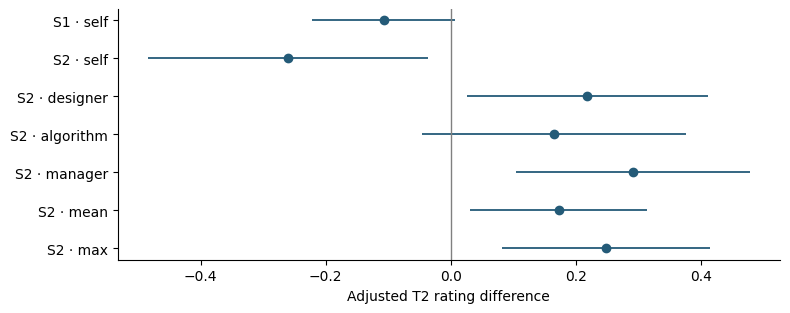

In [10]:
# Diagnose measurement and later attribution
# Method M9 | RQ4
def alpha(frame):
 q=frame.dropna();k=q.shape[1]
 return k/(k-1)*(1-q.var(ddof=1).sum()/q.sum(axis=1).var(ddof=1)) if k>1 else np.nan
diag=[]
for s,z in studies.items():
 for t in [1,2]:
  measures=['self'] if s==1 else ['self','designer','algorithm','manager','mean','max']
  for a in measures:
   v=z[f'{a}{t}'];k=4 if s==1 else (3 if a in ['mean','max'] else 1)
   frame=raw[s][[f'T{t}Responsibility{i}' for i in range(1,5)]] if s==1 else z[[f'{x}{t}' for x in ['designer','algorithm','manager']]]
   al=alpha(frame) if s==1 or a=='mean' else np.nan
   diag.append({'study':s,'time':t,'measure':a,'items_or_candidates':k,'alpha':al,'n':v.notna().sum(),'missing':v.isna().sum(),'mean':v.mean(),'sd':v.std(),'ceiling_share':v.dropna().eq(5).mean()})
table(pd.DataFrame(diag),'RQ4_T2','Alpha is inapplicable to single items and maximums; external-mean alpha is descriptive, not evidence of validity')
later=[]
for s,z in studies.items():
 for a in (['self'] if s==1 else ['self','designer','algorithm','manager','mean','max']):
  later.append({'study':s,'actor':a,**contrast(z,a+'2',' + '+a+'1')})
later=pd.DataFrame(later);later.to_csv(OUT/'RQ4_T2_adjusted_source.csv',index=False)
forest(later,[f'S{r.study} · {r.actor}' for r in later.itertuples()],'Adjusted T2 rating difference','RQ4_F2','T2 responsibility adjusted for T1; T1 is post-assignment, so these conditional contrasts are descriptive')

## Study 2 H3 benchmark and assignment-adjusted sensitivity

The author CSV uses 1 for restricted and 2 for affording autonomy. The analysis first reproduces the seven Figure 5 component coefficients using OLS with conventional intervals. In the sensitivity models, the later responsibility rating is regressed on unethical-choice count, the corresponding earlier rating, and randomized assignment. The published-style model omits assignment. Both are associations. Adding assignment addresses differences between the randomized groups, while other sources of confounding may remain. 

Compare alternative external definitions with the maximum using within-resample paired slope differences on the same participants. Both models and all rating definitions use the same participant bootstrap draws. The intervals are pointwise and exploratory. The designer, algorithm and executive indicators are actor ratings. Their mean is an aggregate, and the maximum is the highest of the three.

In [11]:
# RQ4 | Fit the Study 2 H3 equations and compare the published paths.
columns = "Aut HH Consc T1Des T1Alg T1Exec PR1 T2Des T2Alg T2Exec PR2 UNETHC T1MAX T2MAX".split()
author = pd.read_csv(source_files["Exp2Data.csv"], header=None, names=columns, na_values=-9999)

assert author.shape == (256, 14) and author.notna().all().all()
assert set(author.Aut) == {1, 2}
assert author.UNETHC.between(0, 4).all() and author.UNETHC.mod(1).eq(0).all()
for timepoint in (1, 2):
    components = [f"T{timepoint}{actor}" for actor in ("Des", "Alg", "Exec")]
    assert author[components].max(axis=1).eq(author[f"T{timepoint}MAX"]).all()

# Independently check that the author CSV and SAV have the same construct records.
# Sorting these integer fields makes the check insensitive to file row order.
crosswalk = {
    "UNETHC": "Y", "PR1": "self1", "PR2": "self2",
    "T1Des": "designer1", "T1Alg": "algorithm1", "T1Exec": "manager1",
    "T2Des": "designer2", "T2Alg": "algorithm2", "T2Exec": "manager2",
}
csv_view = author[list(crosswalk)].rename(columns=crosswalk).assign(T=author.Aut.eq(1).astype(int))
check_cols = list(csv_view)
csv_values = csv_view.sort_values(check_cols).to_numpy(dtype=float)
sav_values = studies[2][check_cols].sort_values(check_cols).to_numpy(dtype=float)
if not np.array_equal(csv_values, sav_values):
    raise ValueError("Study 2 CSV/SAV mismatch in assignment, choices, or responsibility ratings.")

paths = [
    ("PR1 ~ Aut", "Aut"),
    ("UNETHC ~ PR1 + Aut", "PR1"),
    ("UNETHC ~ PR1 + Aut", "Aut"),
    ("PR2 ~ UNETHC + PR1", "UNETHC"),
    ("PR2 ~ UNETHC + PR1", "PR1"),
    ("T2MAX ~ UNETHC + T1MAX", "UNETHC"),
    ("T2MAX ~ UNETHC + T1MAX", "T1MAX"),
]
rows = []
# Jolly et al., Figure 5. Published estimates are rounded to two decimals.
published = [0.58, -0.18, -1.15, -0.12, 0.67, 0.08, 0.79]
for (formula, term), published_b in zip(paths, published, strict=True):
    fit = smf.ols(formula, data=author).fit()
    lo, hi = fit.conf_int().loc[term]
    rows.append(dict(equation=formula, term=term, estimate=fit.params[term],
                     low=lo, high=hi, published_B=published_b,
                     delta_B=fit.params[term] - published_b,
                     within_printed_rounding=abs(fit.params[term] - published_b) < 0.005,
                     n=int(fit.nobs)))
h3 = pd.DataFrame(rows)
table(h3, "RQ4_T3", "Study 2 H3 component regressions with 95% OLS intervals and Figure 5 benchmarks")

**RQ4_T3** — Study 2 H3 component regressions with 95% OLS intervals and Figure 5 benchmarks

,equation,term,estimate,low,high,published_B,delta_B,within_printed_rounding,n
0,PR1 ~ Aut,Aut,0.575024,0.304376,0.845673,0.58,-0.004976,True,256
1,UNETHC ~ PR1 + Aut,PR1,-0.179047,-0.325263,-0.032831,-0.18,0.000953,True,256
2,UNETHC ~ PR1 + Aut,Aut,-1.166350,-1.497456,-0.835243,-1.15,-0.016350,False,256
3,PR2 ~ UNETHC + PR1,UNETHC,-0.120965,-0.189831,-0.052099,-0.12,-0.000965,True,256
4,PR2 ~ UNETHC + PR1,PR1,0.675418,0.586988,0.763847,0.67,0.005418,False,256
5,T2MAX ~ UNETHC + T1MAX,UNETHC,0.082283,0.029865,0.134701,0.08,0.002283,True,256
6,T2MAX ~ UNETHC + T1MAX,T1MAX,0.785892,0.711142,0.860643,0.79,-0.004108,True,256


**RQ4_T4** — Choice-count slopes for subsequent responsibility, with paired participant bootstrap 95% intervals

,model,measure,estimate,low,high,n,bootstrap_attempted,bootstrap_valid
0,published_style,Self,-0.120965,-0.185967,-0.051204,256,2000,2000
1,published_style,Maximum external,0.082283,0.033277,0.134331,256,2000,2000
2,published_style,Mean external,0.056288,0.013778,0.098232,256,2000,2000
3,published_style,Designer,0.050096,-0.009092,0.108858,256,2000,2000
4,published_style,Algorithm,0.071646,0.008782,0.138859,256,2000,2000
5,published_style,Executives,0.080767,0.021060,0.143070,256,2000,2000
6,assignment_adjusted,Self,-0.101476,-0.175790,-0.023255,256,2000,2000
7,assignment_adjusted,Maximum external,0.058093,0.010675,0.109788,256,2000,2000
8,assignment_adjusted,Mean external,0.039709,-0.000169,0.083945,256,2000,2000
9,assignment_adjusted,Designer,0.024328,-0.033907,0.085043,256,2000,2000


**RQ4_T5** — Direct paired slope differences; common sample and common bootstrap draws

,model,measure,estimate,low,high,n,bootstrap_attempted,bootstrap_valid
0,published_style,Mean external minus Maximum external,-0.025995,-0.064266,0.013247,256,2000,2000
1,published_style,Designer minus Maximum external,-0.032187,-0.096080,0.029284,256,2000,2000
2,published_style,Algorithm minus Maximum external,-0.010637,-0.070347,0.057410,256,2000,2000
3,published_style,Executives minus Maximum external,-0.001516,-0.055121,0.054063,256,2000,2000
4,published_style,Maximum external minus Self,0.203248,0.109413,0.288666,256,2000,2000
5,published_style,Mean external minus Self,0.177253,0.088684,0.262167,256,2000,2000
6,assignment_adjusted,Mean external minus Maximum external,-0.018384,-0.056220,0.020731,256,2000,2000
7,assignment_adjusted,Designer minus Maximum external,-0.033766,-0.098117,0.027188,256,2000,2000
8,assignment_adjusted,Algorithm minus Maximum external,0.000671,-0.061334,0.070235,256,2000,2000
9,assignment_adjusted,Executives minus Maximum external,-0.010608,-0.069098,0.044015,256,2000,2000


**RQ4_F3** — Study 2 external-measure and external-minus-self slope contrasts; pointwise 95% intervals

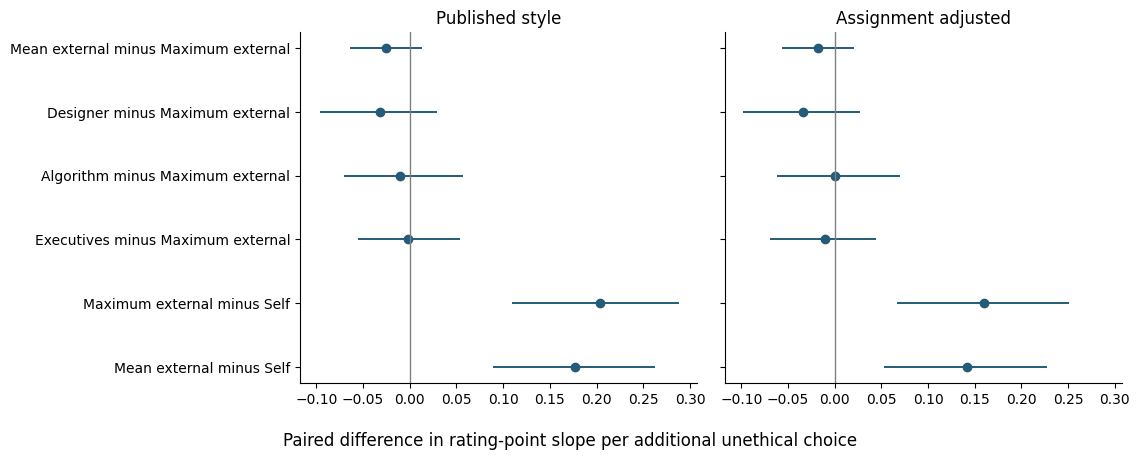

**RQ4_T6** — Change in choice-count slope when randomized assignment is added

,measure,estimate,low,high,n,bootstrap_valid
0,Self,0.019489,-0.013994,0.056449,256,2000
1,Maximum external,-0.024189,-0.048166,-0.002099,256,2000
2,Mean external,-0.016579,-0.037346,0.003071,256,2000
3,Designer,-0.025768,-0.053868,0.000602,256,2000
4,Algorithm,-0.012882,-0.044507,0.018708,256,2000
5,Executives,-0.033281,-0.066147,-0.006596,256,2000


In [12]:
ratings = author.assign(
    T=author.Aut.eq(1).astype(int),
    T1Mean=author[["T1Des", "T1Alg", "T1Exec"]].mean(axis=1),
    T2Mean=author[["T2Des", "T2Alg", "T2Exec"]].mean(axis=1),
)
rating_columns = {
    "Self": ("PR1", "PR2"),
    "Maximum external": ("T1MAX", "T2MAX"),
    "Mean external": ("T1Mean", "T2Mean"),
    "Designer": ("T1Des", "T2Des"),
    "Algorithm": ("T1Alg", "T2Alg"),
    "Executives": ("T1Exec", "T2Exec"),
}
rating_labels = list(rating_columns)
models = ["published_style", "assignment_adjusted"]
required = ["UNETHC", "T"] + [column for pair in rating_columns.values() for column in pair]
common = ratings.dropna(subset=required)

# Shape is model × measure × participant × predictor within each model.
choices = common.UNETHC.to_numpy()
treatment = common["T"].to_numpy()
designs = []
for adjustment in models:
    predictors = []
    for earlier, later in rating_columns.values():
        columns = [np.ones(len(common)), choices, common[earlier].to_numpy()]
        if adjustment == "assignment_adjusted":
            columns.append(treatment)
        predictors.append(np.column_stack(columns))
    designs.append(np.stack(predictors))
outcomes = common[[pair[1] for pair in rating_columns.values()]].to_numpy().T

def estimate_choice_slopes(rows):
    estimates = []
    for model_design in designs:
        row_estimates = []
        for design, response in zip(model_design, outcomes, strict=True):
            coefficients, _, rank, _ = np.linalg.lstsq(design[rows], response[rows], rcond=None)
            if rank != design.shape[1]:
                return None
            row_estimates.append(coefficients[1])
        estimates.append(row_estimates)
    return np.asarray(estimates)

point = estimate_choice_slopes(np.arange(len(common)))
if point is None:
    raise RuntimeError("A full-sample Study 2 responsibility model is rank deficient.")
rng = np.random.default_rng(SEED)
draws = []
for _ in range(BOOTSTRAPS):
    draw = estimate_choice_slopes(rng.integers(len(common), size=len(common)))
    if draw is not None:
        draws.append(draw)
if len(draws) < .99 * BOOTSTRAPS:
    raise RuntimeError(f"Only {len(draws)} of {BOOTSTRAPS} paired bootstrap draws were estimable.")
boot = np.stack(draws)

def summarize_slopes(points, draws, labels):
    low, high = np.quantile(draws, [.025, .975], axis=0)
    return pd.DataFrame([
        {"model": model, "measure": label, "estimate": points[j, k],
         "low": low[j, k], "high": high[j, k], "n": len(common),
         "bootstrap_attempted": BOOTSTRAPS, "bootstrap_valid": len(draws)}
        for j, model in enumerate(models) for k, label in enumerate(labels)
    ])

results = summarize_slopes(point, boot, rating_labels)
table(results, "RQ4_T4", "Choice-count slopes for subsequent responsibility, with paired participant bootstrap 95% intervals")

# Compare external definitions and retain a self-versus-external divergence diagnostic.
comparison_indices = [(index, 1) for index in range(2, len(rating_labels))] + [(1, 0), (2, 0)]
comparison_labels = [f"{rating_labels[a]} minus {rating_labels[b]}" for a, b in comparison_indices]
lhs, rhs = np.asarray(comparison_indices).T
paired = summarize_slopes(point[:, lhs] - point[:, rhs],
                          boot[:, :, lhs] - boot[:, :, rhs], comparison_labels)
table(paired, "RQ4_T5", "Direct paired slope differences; common sample and common bootstrap draws")

fig, axes = plt.subplots(1, 2, figsize=(11.5, 4.6), sharex=True, sharey=True)
for ax, model in zip(axes, models, strict=True):
    shown = paired[paired.model.eq(model)]
    y = np.arange(len(shown))
    ax.hlines(y, shown.low, shown.high, color="#245b78", linewidth=1.4)
    ax.plot(shown.estimate, y, "o", color="#245b78")
    ax.axvline(0, color="gray", linewidth=1)
    ax.set_yticks(y, shown.measure)
    ax.set_title(model.replace("_", " ").capitalize())
axes[0].invert_yaxis()
fig.supxlabel("Paired difference in rating-point slope per additional unethical choice")
figure(fig, "RQ4_F3", "Study 2 external-measure and external-minus-self slope contrasts; pointwise 95% intervals")

shift = point[1] - point[0]
shift_low, shift_high = np.quantile(boot[:, 1] - boot[:, 0], [.025, .975], axis=0)
table(pd.DataFrame({"measure": rating_labels, "estimate": shift, "low": shift_low,
                    "high": shift_high, "n": len(common), "bootstrap_valid": len(boot)}),
      "RQ4_T6", "Change in choice-count slope when randomized assignment is added")

## Study 2 assignment effects on later ratings

For each alternative external measure, compare the within-person difference from the maximum between the two assignment groups. This paired contrast estimates how the released-sample assignment contrast changes with the external-rating definition. It uses no post-assignment covariate.

In [13]:
rows = []
for label in ["Mean external", "Designer", "Algorithm", "Executives"]:
    later = rating_columns[label][1]
    data = common.assign(score_difference=common[later] - common.T2MAX)
    rows.append({"measure": label, **contrast(data, "score_difference")})
table(pd.DataFrame(rows), "RQ2_T3", "Difference in T2 assignment effects, alternative minus maximum")

**RQ2_T3** — Difference in T2 assignment effects, alternative minus maximum

,measure,estimate,low,high,p,n
0,Mean external,-0.053926,-0.192320,0.084467,0.445035,256
1,Designer,-0.021017,-0.234281,0.192248,0.846842,256
2,Algorithm,-0.076491,-0.316486,0.163504,0.532184,256
3,Executives,-0.064272,-0.232798,0.104255,0.454774,256


## Screening sensitivity and full-sample bounds

The author releases contain retained participants. First-pass task checks occur after assignment and can alter the composition of the groups. Report all retained-sample estimates and omission counts. For the unavailable excluded participants, enumerate possible assignment splits and extreme outcomes. The identification bounds carry no sampling uncertainty.

**RQ5_T1** — Published recruitment versus released and retained rows; released is post-exclusion, not an independently verified preregistration rule

,study,rule,recruited,available,retained,status
0,1,no_exclusions,289,276,NaN,unavailable: excluded rows absent
1,1,released,289,276,276.0,released rows only
2,1,hex_perfect,289,276,270.0,released rows only
3,1,first_pass_perfect,289,276,253.0,released rows only
4,2,no_exclusions,268,256,NaN,unavailable: excluded rows absent
5,2,released,268,256,256.0,released rows only
6,2,hex_perfect,268,256,252.0,released rows only
7,2,first_pass_perfect,268,256,227.0,released rows only


**RQ5_F1** — Retained-sample HC3 contrasts; first-pass checks can occur after assignment and alter group composition

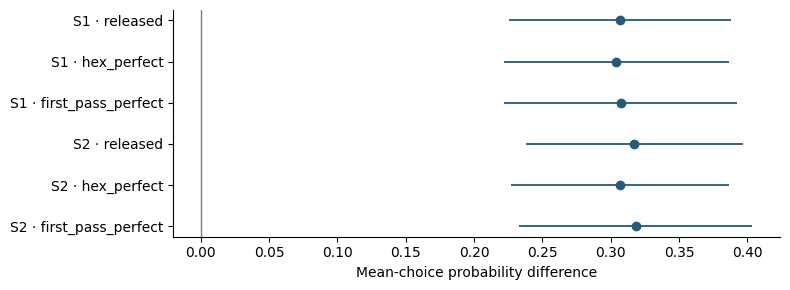

**RQ5_F2** — Worst-case excluded-participant outcomes and allocation; endpoint uses all 13 / 12 excluded participants; no sampling uncertainty included

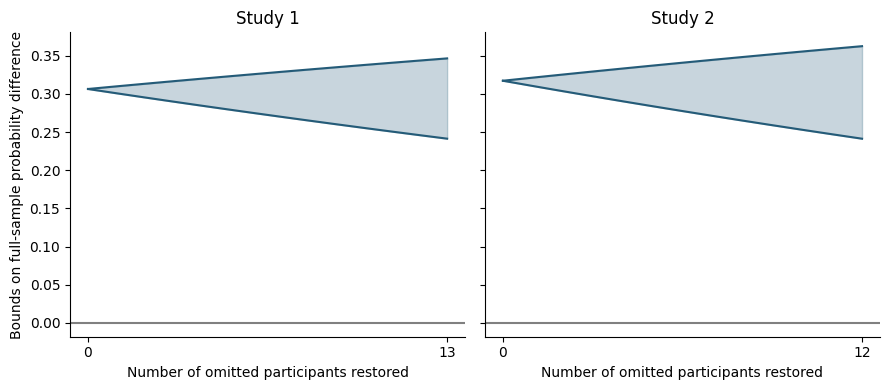

**RQ5_T2** — Screen indicators overlap and must not be summed; repeats are intentionally ignored in the first-pass rule

,study,restricted,available,HEXACO_fail,first_pass_rule_fail,complete_choices
0,1,0,140,3,14,140
1,1,1,136,3,9,136
2,2,0,124,2,9,124
3,2,1,132,2,20,132


In [14]:
# Quantify screening sensitivity and missing exclusions
# Method M10 | RQ5
flow=[];screens=[];diagnostics=[]
for s,z in studies.items():
 recruited={1:289,2:268}[s]
 flow.append({'study':s,'rule':'no_exclusions','recruited':recruited,'available':len(z),'retained':np.nan,'status':'unavailable: excluded rows absent'})
 for rule,mask in rules.items():
  q=z.loc[mask(z)]
  flow.append({'study':s,'rule':rule,'recruited':recruited,'available':len(z),'retained':len(q),'status':'released rows only'})
  screens.append({'study':s,'rule':rule,**contrast(q,'rate')})
 for t in [0,1]:
  q=z[z['T'].eq(t)];diagnostics.append({'study':s,'restricted':t,'available':len(q),'HEXACO_fail':int((~q.hex_pass).sum()),'first_pass_rule_fail':int((~q.first_pass).sum()),'complete_choices':int(q.Y.notna().sum())})
table(pd.DataFrame(flow),'RQ5_T1','Published recruitment versus released and retained rows; released is post-exclusion, not an independently verified preregistration rule')
screens=pd.DataFrame(screens);screens.to_csv(OUT/'RQ5_screen_effects_source.csv',index=False)
forest(screens,[f'S{r.study} · {r.rule}' for r in screens.itertuples()],'Mean-choice probability difference','RQ5_F1','Retained-sample HC3 contrasts; first-pass checks can occur after assignment and alter group composition')
bounds=[]
for s,z in studies.items():
 m={1:289,2:268}[s]-len(z);a=z[z['T'].eq(1)].rate;b=z[z['T'].eq(0)].rate
 for missing in range(m+1):
  lower=[];upper=[]
  for m1 in range(missing+1):
   m0=missing-m1
   lower.append(a.sum()/(len(a)+m1)-(b.sum()+m0)/(len(b)+m0))
   upper.append((a.sum()+m1)/(len(a)+m1)-b.sum()/(len(b)+m0))
  bounds.append({'study':s,'omitted_added':missing,'lower_bound':min(lower),'upper_bound':max(upper)})
bounds=pd.DataFrame(bounds);bounds.to_csv(OUT/'RQ5_bounds_source.csv',index=False)
fig,axes=plt.subplots(1,2,figsize=(9,4),sharey=True)
for ax,s in zip(axes,[1,2]):
 g=bounds[bounds.study.eq(s)];ax.fill_between(g.omitted_added,g.lower_bound,g.upper_bound,alpha=.25,color='#245b78')
 ax.plot(g.omitted_added,g.lower_bound,color='#245b78');ax.plot(g.omitted_added,g.upper_bound,color='#245b78');ax.axhline(0,color='gray')
 ax.set_xlabel('Number of omitted participants restored');ax.set_title(f'Study {s}');ax.set_xticks([0,g.omitted_added.max()])
axes[0].set_ylabel('Bounds on full-sample probability difference')
figure(fig,'RQ5_F2','Worst-case excluded-participant outcomes and allocation; endpoint uses all 13 / 12 excluded participants; no sampling uncertainty included')
table(pd.DataFrame(diagnostics),'RQ5_T2','Screen indicators overlap and must not be summed; repeats are intentionally ignored in the first-pass rule')

## Package aggregate outputs

The archive includes every indexed output, the figure source tables, package versions, and SHA-256 checksums. The full specification ledger includes failed or nonconverged fits if any occur. Historical behavior and H3 benchmarks are descriptive checks against the paper. Exact original joint Mplus estimation, excluded-participant point estimates, and causal effects of the choice count remain outside the available evidence.

In [15]:
import zipfile

expected = {f"RQ{rq}_{suffix}" for rq in range(1, 6) for suffix in ("F1", "F2", "T1", "T2")}
expected.update({"RQ2_T3", "RQ4_F3", "RQ4_T3", "RQ4_T4", "RQ4_T5", "RQ4_T6",
                 "AUDIT", "REPRODUCTION"})
actual = {artifact["id"] for artifact in artifacts}
if actual != expected or len(artifacts) != len(expected):
    raise RuntimeError(f"Output mismatch. Missing: {expected-actual}. Extra: {actual-expected}.")

(OUT / "artifact_index.json").write_text(json.dumps(artifacts, indent=2))
(OUT / "software_versions.json").write_text(json.dumps(versions, indent=2))
(OUT / "requirements.txt").write_text("".join(f"{name}=={version}\n" for name, version in PINNED.items()))
(OUT / "README.txt").write_text("\n".join([
    "Project 16 aggregate results",
    "Exploratory secondary analysis of Jolly et al., DOI 10.1007/s10551-025-06034-5.",
    f"Seed: {SEED}. Paired participant bootstrap draws requested: {BOOTSTRAPS}.",
    "Effects use restricted minus affording assignment unless a benchmark uses the published direction.",
    "Choice-count slopes for later ratings are descriptive associations.",
    "Screening bounds omit sampling uncertainty. The excluded records were unavailable.",
    "See artifact_index.json for captions and RQ1_T1.csv for fit status.",
    "Code dependencies are pinned in requirements.txt.",
]) + "\n")

support = {
    "artifact_index.json", "software_versions.json", "requirements.txt", "README.txt",
    "source_provenance.json", "variable_labels.json",
    "RQ3_item_effects_source.csv", "RQ4_sensitivity_source.csv", "RQ4_T2_adjusted_source.csv",
    "RQ5_screen_effects_source.csv", "RQ5_bounds_source.csv",
}
selected = sorted(support | {artifact["file"] for artifact in artifacts})
for name in selected:
    path = OUT / name
    if not path.is_file() or not path.stat().st_size:
        raise RuntimeError(f"Missing or empty output: {name}")
    if path.suffix == ".pdf" and not path.read_bytes().startswith(b"%PDF-"):
        raise RuntimeError(f"Invalid PDF header: {name}")
(OUT / "SHA256SUMS.txt").write_text("".join(f"{checksum(OUT/name)}  {name}\n" for name in selected))
selected.append("SHA256SUMS.txt")

zip_path = BASE / "project16_results.zip"
temporary_zip = OUT / "project16_results.tmp"
archive_prefix = "project16_results"
with zipfile.ZipFile(temporary_zip, "w", compression=zipfile.ZIP_DEFLATED) as archive:
    for name in selected:
        archive.write(OUT / name, arcname=f"{archive_prefix}/{name}")
with zipfile.ZipFile(temporary_zip) as archive:
    if archive.testzip() is not None or len(archive.namelist()) != len(selected):
        raise RuntimeError("ZIP integrity or file count check failed.")
    for name in selected:
        if hashlib.sha256(archive.read(f"{archive_prefix}/{name}")).hexdigest() != checksum(OUT / name):
            raise RuntimeError(f"ZIP checksum mismatch: {name}")
temporary_zip.replace(zip_path)

for study, group in ok.groupby("study"):
    total = int(spec.study.eq(study).sum())
    print(f"Study {study}: {len(group)}/{total} specifications passed. "
          f"Behavioral probability differences: {group.estimate.min():.3f} to {group.estimate.max():.3f}.")
print(f"Saved {len(artifacts)} indexed outputs and {len(selected) - len(artifacts)} supporting files.")
print(f"Results ZIP: {zip_path}")
display(FileLink(os.path.relpath(zip_path)))

Study 1: 36/36 specifications passed. Behavioral probability differences: 0.273 to 0.307.
Study 2: 36/36 specifications passed. Behavioral probability differences: 0.263 to 0.320.
Saved 28 indexed outputs and 12 supporting files.
Results ZIP: /kaggle/working/project16_results.zip


/kaggle/working/project16_results.zip